# Estudo Comparativo de Classificação Acústica Submarina — Dataset IARA
### Notebook 16: Análise de Complementaridade, Efeito Oráculo e Grau de Consenso no MLP — Classe LARGE

**Autor:** Evandro Rocha (UFRJ / COPPE / PEE)
**Data:** Outubro de 2026

---

## Resumo Executivo da Investigação com Redes Neurais (MLP)

A classe **`LARGE`** (embarcações de grande porte, comprimento $> 100\text{ m}$) é analisada arquivo por arquivo nos 10 folds do protocolo $5\times2$cv, com **particionamento por gravação de áudio (`ID`)**. Atenção: o split é por gravação, **não por navio** — gravações diferentes do mesmo navio (`Ship ID`) podem estar no treino e no teste.

A base são **2.140 instâncias de teste (arquivo × fold)** da classe `LARGE`, que correspondem a **572 gravações únicas** de **417 navios distintos**. Cada gravação aparece no teste **$3{,}74$ vezes em média** (de 1 a 5), e não 5 vezes.

As 4 representações usam a mesma arquitetura **MLP `[32, 16]`**, mas com protocolos de treino diferentes:
1. **MEL (256-D)** e **LOFAR (1024-D):** predições oficiais do pipeline `iara` (`results/trainings/tests/mlp` e `mlp_lofar`), com conjunto de validação e *early stopping*;
2. **HHT (256-D)** e **DEMON (253-D):** MLP PyTorch `[32, 16]` de `scratch/generate_mlp_predictions_and_analysis.py`, **30 épocas fixas**, `seed=42`, **sem validação nem early stopping**.

### Principais resultados (recalculados):
1. **Melhor modelo isolado:** LOFAR com recall de $74{,}72\%$ (1.599 acertos); depois MEL ($68{,}83\%$), HHT ($68{,}08\%$), DEMON ($67{,}34\%$).
2. **Unanimidade (4/4 acertam):** $44{,}44\%$ (951 instâncias); **erro comum (0/4):** $10{,}75\%$ (230).
3. **Oráculo (≥1 de 4 acerta):** $89{,}25\%$ (1.910 instâncias). O oráculo **não é um sistema realizável** (exige saber a resposta certa) e fica **abaixo** do esperado se os erros fossem independentes ($99{,}12\%$): os erros das 4 entradas são **positivamente correlacionados**, e não ortogonais.
4. **Voto real de pluralidade** (empate sorteado) atinge recall de $75{,}84\%$ em `LARGE`; o voto real e o LOFAR isolado são estatisticamente equivalentes (F-test 5x2cv, $p = 0{,}469$; diferença dentro da variação entre folds). O antigo critério "≥2/4" ($78{,}50\%$) contava empates $2\times2$ como acerto e não corresponde a nenhum classificador.
5. **Resgates exclusivos:** o DEMON tem o maior número de instâncias em que só ele acerta (131), mas isso corresponde a 72 gravações (61 navios), e só **9 gravações** são resgatadas exclusivamente pelo DEMON em **todas** as suas aparições no teste.
6. **MEL e LOFAR erram juntos e para o mesmo lado:** quando ambos erram uma instância de `LARGE` (437 casos), preveem a **mesma** classe errada em $64{,}76\%$ deles (283).

In [1]:
# 1. Configuração do ambiente, imports e funções de análise (calculadas a partir das predições em disco)
# Funções de análise de complementaridade, calculadas a partir das predições em disco (iara_results).
import os
import sys
import numpy as np
import pandas as pd
for _p in ('.', 'src', 'notebooks', 'notebooks/src'):
    if os.path.exists(os.path.join(_p, 'iara_results.py')) and os.path.abspath(_p) not in sys.path:
        sys.path.insert(0, os.path.abspath(_p))
import iara_results as R

CLASS_NAMES = {0: 'SMALL', 1: 'MEDIUM', 2: 'LARGE', 3: 'BACKGROUND'}
REPS = ['MEL', 'LOFAR', 'HHT', 'DEMON']
# MLP [32, 16]: MEL/LOFAR = pipeline iara oficial (com validação e early stopping);
#               HHT/DEMON = scratch/generate_mlp_predictions_and_analysis.py (30 épocas, seed 42, sem validação)
MLP_EXPS = {'MEL': 'mlp', 'LOFAR': 'mlp_lofar',
            'HHT': 'mlp_hht_h32-16_e30_4c', 'DEMON': 'mlp_demon_h32-16_e30_4c'}
# SVM Nyström declarado nos NBs 13/12/13 (m=4000 para MEL/HHT/DEMON, m=6000 para LOFAR)
SVM_EXPS = {'MEL': 'svm_nystroem_4000_log_melgram_elasticnet_l1r0.15_C2.0',
            'LOFAR': 'svm_nystroem_6000_lofar_elasticnet_l1r0.15',
            'HHT': 'svm_nystroem_4000_hht_C2.0_elasticnet_l1r0.15_4c',
            'DEMON': 'svm_nystroem_4000_demon_C2.0_elasticnet_l1r0.15_4c'}
VOTE_SEEDS = list(range(10))  # sementes do desempate aleatório do voto de pluralidade


def ship_id_map():
    meta = pd.read_csv(os.path.join(R.ROOT, 'src', 'iara', 'dataset_info', 'iara.csv'), dtype={'ID': str})
    return dict(zip(meta['ID'].astype(int), meta['Ship ID']))


def stacked(exps):
    """Instâncias (arquivo, fold) presentes nas 4 representações, empilhadas sobre os 10 folds."""
    A = R.aligned([exps[r] for r in REPS])
    return pd.concat([d.assign(fold=k) for k, d in A.items()], ignore_index=True)


def complementarity(exps, c):
    cls = CLASS_NAMES[c]
    names = [exps[r] for r in REPS]
    d = stacked(exps)
    d = d[d.Target == c].reset_index(drop=True)
    ships = ship_id_map()
    d['Ship'] = d.File.map(ships)
    H = np.column_stack([d[n].values == c for n in names])
    nh = H.sum(axis=1)
    N = len(d)
    per_file = d.groupby('File').size()
    S = {'cls': cls, 'N': N, 'n_files': int(d.File.nunique()), 'n_ships': int(d.Ship.nunique()),
         'evals_per_file': N / d.File.nunique(), 'evals_min': int(per_file.min()), 'evals_max': int(per_file.max())}
    S['hits'] = {r: int(H[:, i].sum()) for i, r in enumerate(REPS)}
    S['recall'] = {r: 100 * H[:, i].mean() for i, r in enumerate(REPS)}        # agregado sobre as instâncias
    S['recall_fold'] = {r: R.summary(exps[r])[f'R_{cls}'] for r in REPS}       # média ± desvio por fold
    S['best'] = max(REPS, key=S['recall'].get)
    S['oracle_hits'] = int((nh > 0).sum())
    S['oracle'] = 100 * (nh > 0).mean()
    orc = R.oracle_recall(names).loc[cls]
    S['oracle_fold'], S['oracle_indep'] = float(orc.iloc[0]), float(orc.iloc[1])
    S['cons'] = {j: int((nh == j).sum()) for j in (4, 3, 2, 1, 0)}
    S['ge3'] = int((nh >= 3).sum())
    S['ge2'] = int((nh >= 2).sum())
    votes = [R.majority_vote(names, seed=s)[f'R_{cls}'].mean() for s in VOTE_SEEDS]
    S['vote'], S['vote_min'], S['vote_max'] = votes[0], min(votes), max(votes)
    mv0 = R.majority_vote(names, seed=VOTE_SEEDS[0])[f'R_{cls}'].values
    best_fold = R.fold_metrics(exps[S['best']])[f'R_{cls}'].values
    S['vote_fold'] = (mv0.mean(), mv0.std(ddof=0))
    S['vote_F'], S['vote_p'] = R.f_test_5x2(mv0, best_fold)   # F-test 5x2cv sobre o recall da classe
    ex = {}
    for i, r in enumerate(REPS):
        m = H[:, i] & (nh == 1)
        cnt = d.File[m].value_counts()
        always = [f for f, k in cnt.items() if k == per_file[f]]
        ex[r] = {'inst': int(m.sum()), 'files': int(d.File[m].nunique()), 'ships': int(d.Ship[m].nunique()),
                 'files_always': len(always), 'ships_always': len({ships[f] for f in always})}
    S['excl'] = ex
    S['excl_top'] = max(REPS, key=lambda r: ex[r]['inst'])
    conf = {}
    for i, r in enumerate(REPS):
        p = d[exps[r]][~H[:, i]]
        vc = p.value_counts(normalize=True) * 100
        conf[r] = {'n_err': int((~H[:, i]).sum()),
                   **{CLASS_NAMES[k]: float(vc.get(k, 0.0)) for k in range(4) if k != c}}
    S['conf'] = conf
    iM, iL = REPS.index('MEL'), REPS.index('LOFAR')
    both = (~H[:, iM]) & (~H[:, iL])
    S['ml_both_err'] = int(both.sum())
    S['ml_same_err'] = int((d[exps['MEL']].values[both] == d[exps['LOFAR']].values[both]).sum())
    # troca a partir do melhor isolado: o que se perde e o que se resgata ao usar outra entrada
    ib = REPS.index(S['best'])
    S['switch'] = {r: {'keep': int((H[:, ib] & H[:, i]).sum()), 'lose': int((H[:, ib] & ~H[:, i]).sum()),
                       'gain': int((~H[:, ib] & H[:, i]).sum())} for i, r in enumerate(REPS) if i != ib}
    return S


def vote_global(exps):
    """SP global (4 classes) do voto real de pluralidade vs. melhor modelo isolado em SP, com F-test 5x2cv."""
    names = [exps[r] for r in REPS]
    mv = R.majority_vote(names, seed=VOTE_SEEDS[0])
    sp = {r: R.summary(exps[r])['SP'] for r in REPS}
    best = max(REPS, key=lambda r: sp[r][0])
    F, p = R.f_test_5x2(mv['SP'].values, exps[best])
    return {'vote_sp': (mv['SP'].mean(), mv['SP'].std(ddof=0)), 'best': best, 'best_sp': sp[best],
            'F': F, 'p': p, 'sp': sp}


def reprodutibilidade():
    """Compara as predições atuais de HHT/DEMON com as da versão anterior (pickle de backup de 15/10/2026)."""
    import pickle
    from collections import Counter
    pth = os.path.join(R.ROOT, 'data', 'iara_processed', '_backup_20261020', 'mlp_all_representations_predictions.pkl')
    if not os.path.exists(pth):
        return None
    with open(pth, 'rb') as f:
        old = pickle.load(f)
    rows = []
    for rep, key in [('HHT', 'hht'), ('DEMON', 'demon')]:
        exp = MLP_EXPS[rep]
        diff = tot = 0
        sp_old, sp_low = [], []
        for k in range(10):
            o, tg = old[key][k], old['targets'][k]
            files = list(o)
            sp_old.append(R._metrics(np.array([tg[f] for f in files]), np.array([o[f] for f in files]))['SP'])
            w = pd.read_csv(os.path.join(R.exp_dir(exp), 'eval', f'fold_{k}', f'{exp}_multiclass_test.csv'),
                            usecols=['File', 'Target', 'Prediction'])
            g = w.groupby('File')
            y = g.Target.agg(lambda s: Counter(s).most_common(1)[0][0])
            p = g.Prediction.agg(lambda s: int(np.argmax(np.bincount(s, minlength=4))))  # mesmo desempate do pickle
            sp_low.append(R._metrics(y.values, p.values)['SP'])
            tot += len(files)
            diff += sum(int(o[f]) != int(p.get(f, -1)) for f in files)
        rows.append({'Representação': rep, 'SP versão anterior (pickle 15/10)': round(float(np.mean(sp_old)), 2),
                     'SP atual (empate -> 1ª janela, pipeline iara)': round(R.summary(exp)['SP'][0], 2),
                     'SP atual (empate -> menor índice, como o script)': round(float(np.mean(sp_low)), 2),
                     'Instâncias c/ predição diferente (mesmo desempate)': diff, 'Instâncias': tot})
    return pd.DataFrame(rows).set_index('Representação')


def tabela_acertos(S):
    rows = [{'Representação': r, 'Acertos': S['hits'][r], 'Recall agregado (%)': round(S['recall'][r], 2),
             'Recall por fold (%)': R.fmt(S['recall_fold'][r])} for r in REPS]
    rows.append({'Representação': 'ORÁCULO (≥1 de 4 acerta; não realizável)', 'Acertos': S['oracle_hits'],
                 'Recall agregado (%)': round(S['oracle'], 2), 'Recall por fold (%)': f"{S['oracle_fold']:.2f}"})
    rows.append({'Representação': 'Oráculo esperado c/ erros independentes', 'Acertos': np.nan,
                 'Recall agregado (%)': np.nan, 'Recall por fold (%)': f"{S['oracle_indep']:.2f}"})
    rows.append({'Representação': 'Voto real de pluralidade (empate sorteado)', 'Acertos': np.nan,
                 'Recall agregado (%)': np.nan,
                 'Recall por fold (%)': f"{S['vote']:.2f} (10 sementes: {S['vote_min']:.2f}–{S['vote_max']:.2f})"})
    return pd.DataFrame(rows).set_index('Representação')


def tabela_consenso(S):
    lab = {4: '4 de 4 (unanimidade)', 3: '3 de 4', 2: '2 de 4', 1: '1 de 4 (resgate exclusivo)',
           0: '0 de 4 (erro comum)'}
    return pd.DataFrame([{'Nível de consenso': lab[j], 'Instâncias': n, '% do total': round(100 * n / S['N'], 2),
                          '% dos acertos do oráculo': round(100 * n / S['oracle_hits'], 2) if j > 0 else np.nan}
                         for j, n in S['cons'].items()]).set_index('Nível de consenso')


def tabela_exclusivos(S):
    return pd.DataFrame([{'Representação': r, 'Instâncias (arquivo×fold)': e['inst'],
                          '% das instâncias': round(100 * e['inst'] / S['N'], 2),
                          'Gravações únicas': e['files'], 'Navios únicos (Ship ID)': e['ships'],
                          'Gravações exclusivas em todas as aparições': e['files_always'],
                          'Navios dessas gravações': e['ships_always']}
                         for r, e in S['excl'].items()]).set_index('Representação')


def tabela_confusao(S):
    rows = []
    for r in REPS:
        c = S['conf'][r]
        rows.append({'Representação': r, 'Erros': c['n_err'],
                     **{f'→ {k} (%)': round(v, 2) for k, v in c.items() if k != 'n_err'}})
    return pd.DataFrame(rows).set_index('Representação')


def tabela_troca(S):
    return pd.DataFrame([{'Trocar para': r, f"Mantém acertos do {S['best']}": v['keep'],
                          f"Perde acertos do {S['best']}": v['lose'], f"Resgata erros do {S['best']}": v['gain'],
                          'Saldo líquido': v['gain'] - v['lose']} for r, v in S['switch'].items()]).set_index('Trocar para')


def tabela_svm_vs_mlp(Ssvm, Smlp):
    def col(S):
        b = S['best']
        return {'Melhor isolado (recall agregado)': f"{S['recall'][b]:.2f}% ({b})",
                'Oráculo observado (média por fold)': f"{S['oracle_fold']:.2f}%",
                'Oráculo esperado c/ erros independentes': f"{S['oracle_indep']:.2f}%",
                'Unanimidade 4/4': f"{100 * S['cons'][4] / S['N']:.2f}% ({S['cons'][4]})",
                'Resgate exclusivo 1/4': f"{100 * S['cons'][1] / S['N']:.2f}% ({S['cons'][1]})",
                'Erro comum 0/4': f"{100 * S['cons'][0] / S['N']:.2f}% ({S['cons'][0]})",
                'Maior resgatador exclusivo (instâncias)': f"{S['excl_top']} ({S['excl'][S['excl_top']]['inst']})",
                '"≥2/4" (conta empates 2×2 como acerto)': f"{100 * S['ge2'] / S['N']:.2f}%",
                'Voto real de pluralidade (média por fold)': f"{S['vote']:.2f}%"}
    return pd.DataFrame({'SVM Nyström': col(Ssvm), 'MLP [32, 16]': col(Smlp)})

import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 13,
                     'xtick.labelsize': 10, 'ytick.labelsize': 10, 'figure.titlesize': 15, 'figure.dpi': 150})
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 20)

CLASSE = 2  # LARGE
print('Experimentos MLP:', MLP_EXPS)

Experimentos MLP: {'MEL': 'mlp', 'LOFAR': 'mlp_lofar', 'HHT': 'mlp_hht_h32-16_e30_4c', 'DEMON': 'mlp_demon_h32-16_e30_4c'}


## 2. Metodologia Experimental e Base de Dados de Teste

- **Instâncias:** cada linha é um par (gravação, fold) da classe `LARGE` presente no teste das 4 representações: 2.140 instâncias = 572 gravações únicas = 417 navios (`Ship ID` de `src/iara/dataset_info/iara.csv`). As contagens de "acertos" e "resgates" abaixo são **instâncias**, não gravações nem navios distintos.
- **Predição por arquivo:** voto majoritário das janelas com `Counter.most_common` (empate $\rightarrow$ classe da 1ª janela), como em `src/iara/ml/models/trainer.py`. O script de HHT/DEMON desempatava pelo menor índice de classe (`argmax(bincount)`), por isso o SP do DEMON pode diferir ligeiramente do log do script. O experimento HHT (`mlp_hht_h32-16_e30_4c`) está disponível só em granularidade de arquivo (restaurado do pickle; ver `config.json`), o que é suficiente para todas as análises por arquivo deste notebook.
- **Protocolos diferentes:** MEL/LOFAR usam validação e early stopping (pipeline `iara`); HHT/DEMON usam 30 épocas fixas sem validação. Parte da diferença entre representações pode vir do protocolo de treino, e não só da entrada.
- **Não determinismo (GPU):** HHT e DEMON foram re-treinados em 20/10/2026 e **não reproduzem exatamente** a versão anterior (pickle de 15/10): SP do HHT $56{,}97$ $\rightarrow$ $56{,}70$ (1.146 das 6.390 instâncias arquivo×fold com predição diferente) e do DEMON $53{,}23$ $\rightarrow$ $53{,}16$ com o desempate do script (1.418 instâncias diferentes). Mesmo com `seed=42`, o treino na GPU não é determinístico; todas as interseções, resgates e oráculos abaixo foram recalculados com as predições atuais.
- **SP global (4 classes):** MEL $64{,}74 \pm 2{,}05$, LOFAR $66{,}24 \pm 1{,}78$, HHT $56{,}70 \pm 1{,}36$, DEMON $53{,}06 \pm 2{,}39$. Para referência, a Tabela 7 do artigo (Silva et al., IEEE Access 2025) reporta SP $63{,}38 \pm 1{,}81$ (MLP MEL) e $66{,}51 \pm 1{,}39$ (MLP LOFAR); os MLPs locais do pipeline `iara` (arquitetura do artigo, mas paciência 16 em vez de 8 e, no LOFAR, dropout 0,2 em vez de 0) dão $64{,}74 \pm 2{,}05$ e $66{,}24 \pm 1{,}78$.

In [2]:
# 2. Métricas globais dos 4 MLPs (SP, ACC = acurácia balanceada; média ± desvio nos 10 folds) e reprodutibilidade
display(R.table([(f'MLP {r}', MLP_EXPS[r]) for r in REPS], metrics=('SP', 'ACC', 'F1')))
print('Tabela 7 do artigo (SP):', {r: R.ARTICLE_TABLE7[('MLP', r)]['SP'] for r in ('MEL', 'LOFAR')})
display(reprodutibilidade())

S = complementarity(MLP_EXPS, CLASSE)
print(f"{S['cls']}: {S['N']} instâncias (arquivo×fold) = {S['n_files']} gravações únicas = {S['n_ships']} navios; "
      f"{S['evals_per_file']:.2f} aparições por gravação em média (mín {S['evals_min']}, máx {S['evals_max']})")
display(tabela_acertos(S))
display(tabela_consenso(S))

,SP,ACC,F1,SMALL,MEDIUM,LARGE,BACKGROUND,Experimento
Modelo,,,,,,,,
MLP MEL,64.74 ± 2.05,65.73 ± 1.90,64.19 ± 2.14,44.78,64.09,68.83,85.20,mlp
MLP LOFAR,66.24 ± 1.78,67.22 ± 1.65,66.42 ± 1.87,46.35,61.48,74.72,86.33,mlp_lofar
MLP HHT,56.70 ± 1.36,58.81 ± 0.97,55.58 ± 1.55,28.88,58.79,68.08,79.49,mlp_hht_h32-16_e30_4c
MLP DEMON,53.06 ± 2.39,55.14 ± 1.68,52.20 ± 2.28,32.19,43.29,67.34,77.76,mlp_demon_h32-16_e30_4c


Tabela 7 do artigo (SP): {'MEL': (63.38, 1.81), 'LOFAR': (66.51, 1.39)}


,SP versão anterior (pickle 15/10),"SP atual (empate -> 1ª janela, pipeline iara)","SP atual (empate -> menor índice, como o script)",Instâncias c/ predição diferente (mesmo desempate),Instâncias
Representação,,,,,
HHT,56.97,56.70,56.76,1146,6390
DEMON,53.23,53.06,53.16,1418,6390


LARGE: 2140 instâncias (arquivo×fold) = 572 gravações únicas = 417 navios; 3.74 aparições por gravação em média (mín 1, máx 5)


,Acertos,Recall agregado (%),Recall por fold (%)
Representação,,,
MEL,1473.0,68.83,68.83 ± 5.77
LOFAR,1599.0,74.72,74.72 ± 4.30
HHT,1457.0,68.08,68.08 ± 3.17
DEMON,1441.0,67.34,67.34 ± 8.96
ORÁCULO (≥1 de 4 acerta; não realizável),1910.0,89.25,89.25
Oráculo esperado c/ erros independentes,NaN,NaN,99.12
Voto real de pluralidade (empate sorteado),NaN,NaN,75.84 (10 sementes: 75.19–76.21)


,Instâncias,% do total,% dos acertos do oráculo
Nível de consenso,,,
4 de 4 (unanimidade),951,44.44,49.79
3 de 4,478,22.34,25.03
2 de 4,251,11.73,13.14
1 de 4 (resgate exclusivo),230,10.75,12.04
0 de 4 (erro comum),230,10.75,NaN


## 3. O Efeito Oráculo no MLP: Recall Individual vs. Oráculo

Isoladamente, o **LOFAR** lidera em `LARGE` com recall de $74{,}72\%$ (1.599 acertos), seguido por MEL ($68{,}83\%$), HHT ($68{,}08\%$), DEMON ($67{,}34\%$).

A união das 4 representações (**oráculo**: conta acerto se qualquer uma acerta) chega a $89{,}25\%$ (1.910 instâncias), $14{,}5$ p.p. acima do melhor isolado. Esse número deve ser lido com cautela:
- o oráculo **não é realizável** — escolher a entrada certa exige conhecer o rótulo;
- mesmo preditores sem relação entre si elevam o oráculo: com os recalls individuais acima e **erros independentes**, o esperado seria $99{,}12\%$ (média por fold, $1-\prod_i(1-r_i)$), contra $89{,}25\%$ observados. O oráculo observado fica **abaixo** do esperado, ou seja, as entradas tendem a errar **nos mesmos áudios** — a evidência é de erros correlacionados, não de informação ortogonal.

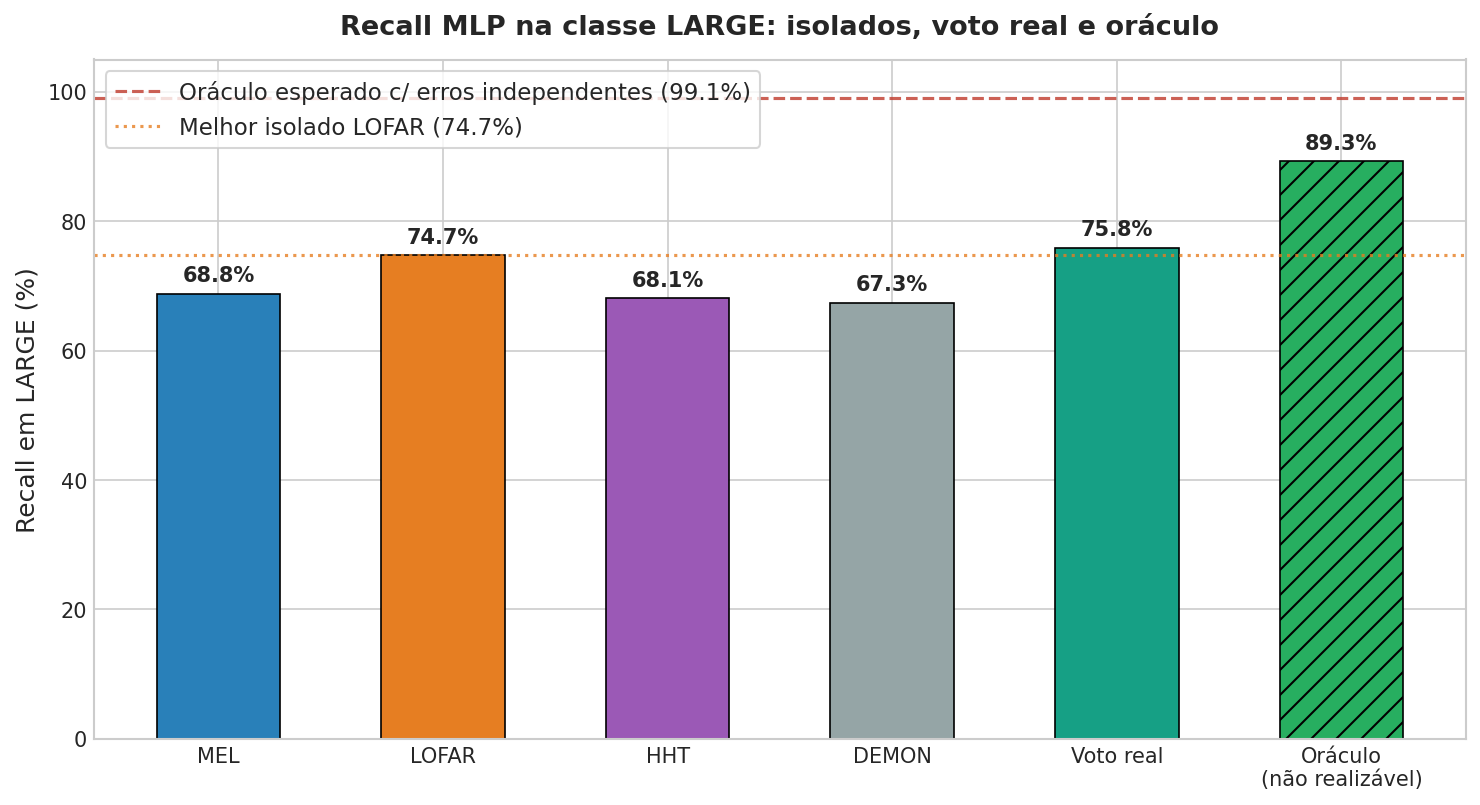

In [3]:
# 3. Gráfico: recall isolado vs. oráculo observado, oráculo esperado (erros independentes) e voto real
labels = [f'{r}' for r in REPS] + ['Voto real', 'Oráculo\n(não realizável)']
vals = [S['recall'][r] for r in REPS] + [S['vote'], S['oracle']]
colors = ['#2980b9', '#e67e22', '#9b59b6', '#95a5a6', '#16a085', '#27ae60']
plt.figure(figsize=(10, 5.5))
bars = plt.bar(labels, vals, color=colors, width=0.55, edgecolor='black', linewidth=0.8)
bars[-1].set_hatch('//')
plt.axhline(S['oracle_indep'], color='#c0392b', linestyle='--', lw=1.5, alpha=0.8,
            label=f"Oráculo esperado c/ erros independentes ({S['oracle_indep']:.1f}%)")
plt.axhline(S['recall'][S['best']], color='#e67e22', linestyle=':', lw=1.5, alpha=0.8,
            label=f"Melhor isolado {S['best']} ({S['recall'][S['best']]:.1f}%)")
plt.title(f"Recall MLP na classe {S['cls']}: isolados, voto real e oráculo", fontweight='bold', pad=12)
plt.ylabel(f"Recall em {S['cls']} (%)")
plt.ylim(0, 105)
for bar in bars:
    h = bar.get_height()
    plt.annotate(f'{h:.1f}%', xy=(bar.get_x() + bar.get_width() / 2, h), xytext=(0, 4), textcoords='offset points',
                 ha='center', va='bottom', fontsize=10, fontweight='bold')
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

## 4. Análise de Grau de Consenso e Risco do Efeito Reverso em `LARGE` no MLP

- **Unanimidade (4/4 certas):** 951 instâncias ($44{,}44\%$)
- **3/4 certas:** 478 instâncias ($22{,}34\%$)
- **Consenso dividido (2/4 certas):** 251 instâncias ($11{,}73\%$)
- **Resgate exclusivo (1/4 certa):** 230 instâncias ($10{,}75\%$)
- **Erro comum (0/4 certas):** 230 instâncias ($10{,}75\%$)

$12{,}04\%$ dos acertos do oráculo dependem de uma única entrada.

### Votação por consenso no MLP:
- **Unanimidade (4/4):** $44{,}44\%$;
- **Maioria estrita ($\ge 3/4$):** $66{,}78\%$ (1.429 instâncias);
- **"$\ge 2/4$" (`c4 + c3 + c2`):** $78{,}50\%$ — **não é um classificador**: conta como acerto os empates $2\times2$, nos quais um voto real escolheria a classe errada metade das vezes, e ignora como os votos errados se distribuem;
- **Voto real de pluralidade** (empate sorteado, `R.majority_vote`): recall de $75{,}84 \pm 3{,}61$ em `LARGE` (variação entre 10 sementes de desempate: $75{,}19$–$76{,}21$), contra $74{,}72 \pm 4{,}30$ do LOFAR isolado — o voto real e o LOFAR isolado são estatisticamente equivalentes (F-test 5x2cv, $p = 0{,}469$; diferença dentro da variação entre folds);
- **Oráculo ($\ge 1/4$):** $89{,}25\%$ (não realizável).

No SP global de 4 classes, o voto real das 4 MLPs obtém $66{,}01 \pm 1{,}79$, contra $66{,}24 \pm 1{,}78$ do melhor isolado (LOFAR): o voto e o melhor isolado são estatisticamente equivalentes (F-test 5x2cv, $p = 0{,}485$; diferença dentro da variação entre folds).

### 4.2 O efeito reverso a partir do LOFAR (1.599 acertos)
- **Trocar para MEL:** perde 230 e resgata 104 (saldo líquido: -126 instâncias);
- **Trocar para HHT:** perde 260 e resgata 118 (saldo líquido: -142 instâncias);
- **Trocar para DEMON:** perde 397 e resgata 239 (saldo líquido: -158 instâncias);

Trocar o LOFAR por outra representação, sem um critério de escolha por instância, reduz os acertos em `LARGE`.

,Mantém acertos do LOFAR,Perde acertos do LOFAR,Resgata erros do LOFAR,Saldo líquido
Trocar para,,,,
MEL,1369,230,104,-126
HHT,1339,260,118,-142
DEMON,1202,397,239,-158


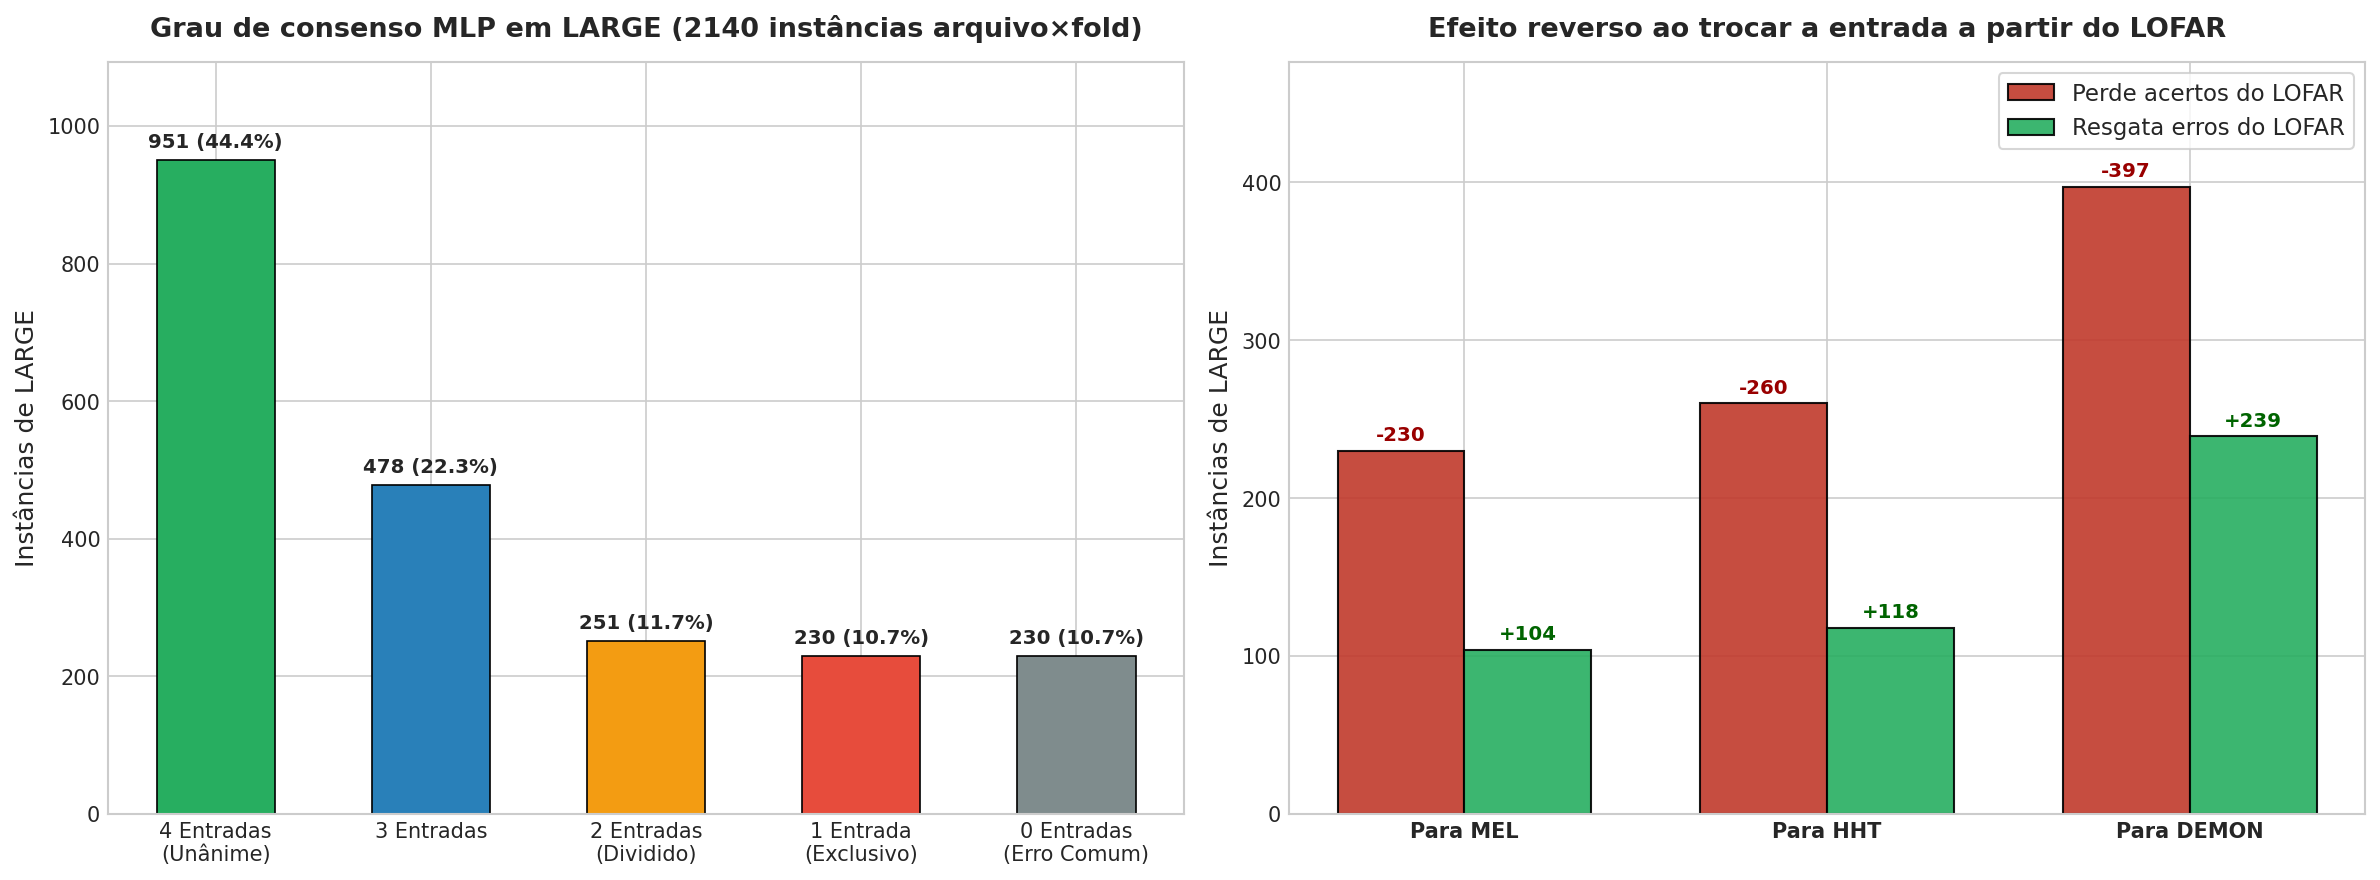

In [4]:
# 4. Visualização do grau de consenso no MLP
labels_cons = ['4 Entradas\n(Unânime)', '3 Entradas', '2 Entradas\n(Dividido)', '1 Entrada\n(Exclusivo)', '0 Entradas\n(Erro Comum)']
counts_cons = [S['cons'][j] for j in (4, 3, 2, 1, 0)]
colors_cons = ['#27ae60', '#2980b9', '#f39c12', '#e74c3c', '#7f8c8d']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

bars = ax1.bar(labels_cons, counts_cons, color=colors_cons, edgecolor='black', linewidth=0.8, width=0.55)
ax1.set_title(f"Grau de consenso MLP em {S['cls']} ({S['N']} instâncias arquivo×fold)", fontweight='bold', pad=12)
ax1.set_ylabel(f"Instâncias de {S['cls']}")
ax1.set_ylim(0, max(counts_cons) * 1.15)
for bar, n in zip(bars, counts_cons):
    ax1.annotate(f'{n} ({100 * n / S["N"]:.1f}%)', xy=(bar.get_x() + bar.get_width() / 2, n), xytext=(0, 4),
                 textcoords='offset points', ha='center', va='bottom', fontsize=9.5, fontweight='bold')

display(tabela_troca(S))
dest = list(S['switch'])
perdas = [S['switch'][r]['lose'] for r in dest]
ganhos = [S['switch'][r]['gain'] for r in dest]
x = np.arange(len(dest)); w = 0.35
r1 = ax2.bar(x - w / 2, perdas, w, label=f"Perde acertos do {S['best']}", color='#c0392b', alpha=0.9, edgecolor='black')
r2 = ax2.bar(x + w / 2, ganhos, w, label=f"Resgata erros do {S['best']}", color='#27ae60', alpha=0.9, edgecolor='black')
ax2.set_title(f"Efeito reverso ao trocar a entrada a partir do {S['best']}", fontweight='bold', pad=12)
ax2.set_ylabel(f"Instâncias de {S['cls']}")
ax2.set_xticks(x); ax2.set_xticklabels([f'Para {r}' for r in dest], fontweight='bold')
ax2.set_ylim(0, max(perdas + ganhos) * 1.2)
ax2.legend(loc='upper right', frameon=True)
for rect, sign, col in [(r, '-', '#900') for r in r1] + [(r, '+', '#006400') for r in r2]:
    h = rect.get_height()
    ax2.annotate(f'{sign}{int(h)}', xy=(rect.get_x() + rect.get_width() / 2, h), xytext=(0, 3),
                 textcoords='offset points', ha='center', va='bottom', fontsize=9.5, fontweight='bold', color=col)

plt.tight_layout()
plt.show()

## 5. Resgates Exclusivos no MLP em `LARGE`

Em **230 instâncias de `LARGE` ($10{,}75\%$)**, três entradas falharam e apenas uma acertou:

- **DEMON:** 131 instâncias ($6{,}12\%$) = 72 gravações / 61 navios; exclusivas em todas as aparições: 9 gravação(ões)
- **LOFAR:** 44 instâncias ($2{,}06\%$) = 32 gravações / 28 navios; exclusivas em todas as aparições: 2 gravação(ões)
- **HHT:** 31 instâncias ($1{,}45\%$) = 24 gravações / 21 navios; exclusivas em todas as aparições: 2 gravação(ões)
- **MEL:** 24 instâncias ($1{,}12\%$) = 18 gravações / 18 navios; exclusivas em todas as aparições: 1 gravação(ões)

O **DEMON** tem o maior número de resgates exclusivos (131 instâncias). O texto anterior falava em "117 navios"; na verdade a contagem é de instâncias arquivo×fold: hoje são 131 instâncias = **72 gravações** de **61 navios**, e apenas **9 gravações** (9 navios) são resgatadas exclusivamente pelo DEMON em todas as suas aparições no teste.

Os resgates exclusivos são contados por **instância (arquivo × fold)** e são instáveis entre folds: a mesma gravação pode ser resgatada só pelo DEMON num fold e por outra entrada (ou por nenhuma) em outro. Também não são evidência de informação ortogonal: uma entrada mais fraca e com erros diferentes gera resgates exclusivos mesmo ao acaso (ver o oráculo esperado na seção 3).

A hipótese de que o DEMON capta a modulação de eixo/pás de motores lentos é plausível, mas **não foi testada** aqui (não há análise das frequências de modulação desses arquivos).

,Instâncias (arquivo×fold),% das instâncias,Gravações únicas,Navios únicos (Ship ID),Gravações exclusivas em todas as aparições,Navios dessas gravações
Representação,,,,,,
MEL,24,1.12,18,18,1,1
LOFAR,44,2.06,32,28,2,2
HHT,31,1.45,24,21,2,2
DEMON,131,6.12,72,61,9,9


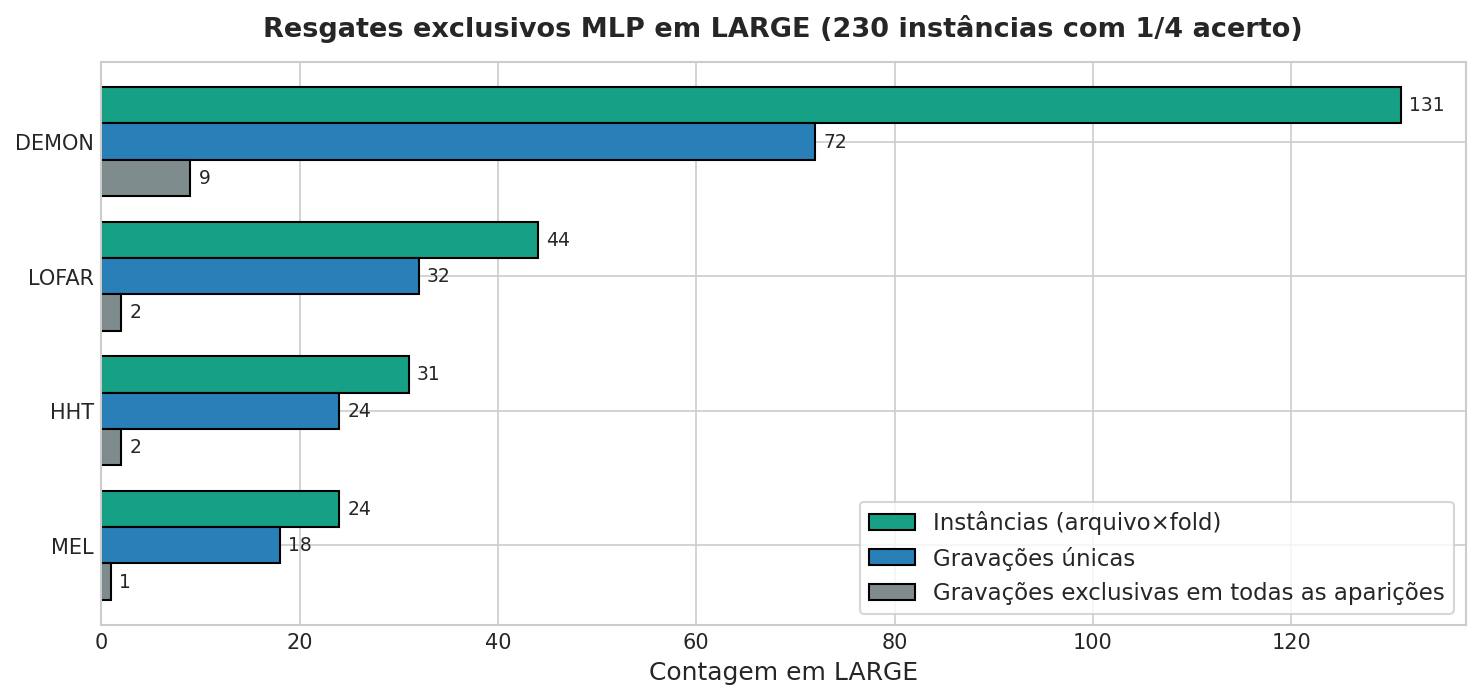

In [5]:
# 5. Resgates exclusivos por representação: instâncias vs. gravações únicas vs. navios
display(tabela_exclusivos(S))
order = sorted(REPS, key=lambda r: S['excl'][r]['inst'])
inst = [S['excl'][r]['inst'] for r in order]
grav = [S['excl'][r]['files'] for r in order]
alw = [S['excl'][r]['files_always'] for r in order]
y = np.arange(len(order)); h = 0.27
plt.figure(figsize=(10, 4.8))
plt.barh(y + h, inst, h, label='Instâncias (arquivo×fold)', color='#16a085', edgecolor='black')
plt.barh(y, grav, h, label='Gravações únicas', color='#2980b9', edgecolor='black')
plt.barh(y - h, alw, h, label='Gravações exclusivas em todas as aparições', color='#7f8c8d', edgecolor='black')
for yy, vals in zip(y, zip(inst, grav, alw)):
    for off, v in zip((h, 0, -h), vals):
        plt.annotate(str(v), xy=(v, yy + off), xytext=(4, 0), textcoords='offset points', va='center', fontsize=9)
plt.yticks(y, order)
plt.xlabel(f"Contagem em {S['cls']}")
plt.title(f"Resgates exclusivos MLP em {S['cls']} ({S['cons'][1]} instâncias com 1/4 acerto)", fontweight='bold', pad=12)
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

## 6. Padrões de Erro em `LARGE`: Para Onde Cada Entrada Envia a Embarcação no MLP?

- **MEL** (667 erros): $47{,}68\%$ $\rightarrow$ `MEDIUM`, $40{,}78\%$ $\rightarrow$ `SMALL`, $11{,}54\%$ $\rightarrow$ `BACKGROUND`
- **LOFAR** (541 erros): $50{,}28\%$ $\rightarrow$ `SMALL`, $39{,}37\%$ $\rightarrow$ `MEDIUM`, $10{,}35\%$ $\rightarrow$ `BACKGROUND`
- **HHT** (683 erros): $38{,}65\%$ $\rightarrow$ `MEDIUM`, $37{,}77\%$ $\rightarrow$ `SMALL`, $23{,}57\%$ $\rightarrow$ `BACKGROUND`
- **DEMON** (699 erros): $52{,}36\%$ $\rightarrow$ `SMALL`, $27{,}04\%$ $\rightarrow$ `BACKGROUND`, $20{,}60\%$ $\rightarrow$ `MEDIUM`

MEL erra `LARGE` principalmente para `MEDIUM` e LOFAR para `SMALL`, mas isso **não** significa que errem em direções opostas nos mesmos áudios: nas 437 instâncias em que **ambos** erram, preveem a **mesma** classe errada em 283 ($64{,}76\%$).

As explicações mecânicas antes associadas a cada destino de erro (energia de propulsores, exaustão, dispersão entre IMFs) eram especulativas e foram retiradas: estes dados mostram **para onde** vão os erros, não **por quê**.

,Erros,→ SMALL (%),→ MEDIUM (%),→ BACKGROUND (%)
Representação,,,,
MEL,667,40.78,47.68,11.54
LOFAR,541,50.28,39.37,10.35
HHT,683,37.77,38.65,23.57
DEMON,699,52.36,20.60,27.04


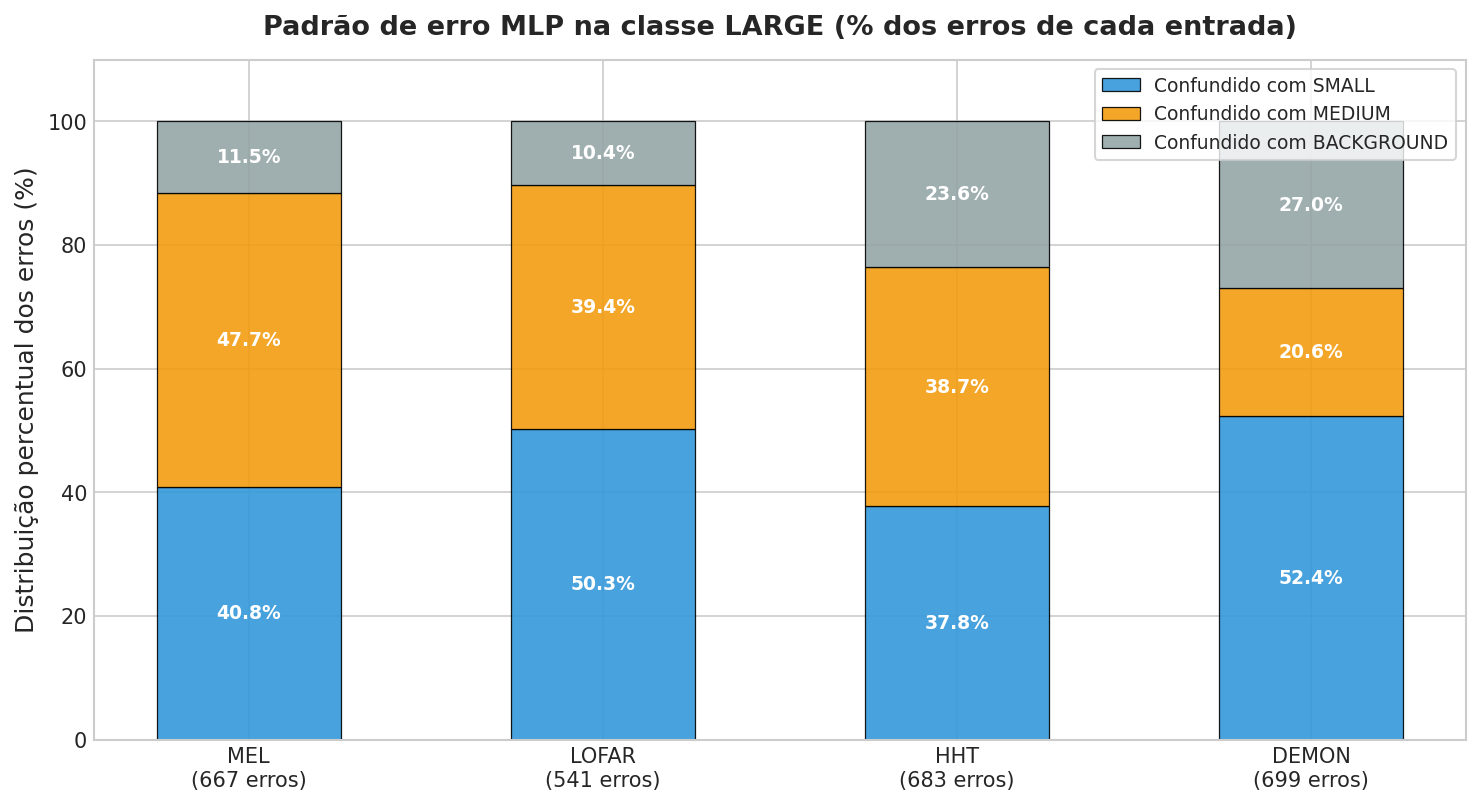

In [6]:
# 6. Destino do erro em LARGE por representação (MLP)
display(tabela_confusao(S))
dests = [k for k in S['conf'][REPS[0]] if k != 'n_err']
cores = {'SMALL': '#3498db', 'MEDIUM': '#f39c12', 'LARGE': '#e74c3c', 'BACKGROUND': '#95a5a6'}
plt.figure(figsize=(10, 5.5))
bottom = np.zeros(len(REPS))
for k in dests:
    v = np.array([S['conf'][r][k] for r in REPS])
    plt.bar([f"{r}\n({S['conf'][r]['n_err']} erros)" for r in REPS], v, 0.52, bottom=bottom,
            label=f'Confundido com {k}', color=cores[k], alpha=0.9, edgecolor='black', linewidth=0.6)
    for i, (b, vv) in enumerate(zip(bottom, v)):
        if vv > 4:
            plt.text(i, b + vv / 2, f'{vv:.1f}%', ha='center', va='center', fontsize=9, fontweight='bold', color='white')
    bottom += v
plt.title(f"Padrão de erro MLP na classe {S['cls']} (% dos erros de cada entrada)", fontweight='bold', pad=12)
plt.ylabel('Distribuição percentual dos erros (%)')
plt.ylim(0, 110)
plt.legend(loc='upper right', frameon=True, fontsize=9)
plt.tight_layout()
plt.show()

## 7. Painel Consolidado (MLP)

O painel de 4 quadrantes antes exibido aqui (`reports/analise_complementaridade_mlp_large_oraculo.png`) foi gerado em 15/10/2026 com as predições anteriores de HHT/DEMON e **não corresponde aos números atuais**; por isso não é mais exibido. Os gráficos das seções 3 a 6 são gerados a partir das predições em disco.

## 8. Comparativo Cruzado: `LARGE` no SVM (Notebook 13) vs. `LARGE` no MLP (Notebook 16)

SVM Nyström recalculado com os experimentos declarados no Notebook 13 ($m=4000$ para MEL, HHT e DEMON; $m=6000$ para LOFAR): MEL SP $63{,}78 \pm 1{,}14$, LOFAR SP $63{,}83 \pm 1{,}91$, HHT SP $52{,}31 \pm 6{,}94$, DEMON SP $30{,}25 \pm 21{,}66$.

**Atenção:** no SVM, HHT tem SP $52{,}31 \pm 6{,}94$ (mín. por fold $34{,}6$); DEMON tem SP $30{,}25 \pm 21{,}66$ (mín. por fold $0{,}0$; SP $= 0$, isto é, alguma classe com recall nulo, em 3 dos 10 folds) — modelo(s) instável(is) entre folds, que não deve(m) servir de referência para anunciar ganho. Isso afeta o consenso, os resgates exclusivos e o oráculo do SVM; a comparação abaixo deve ser lida com essa ressalva.

| Dimensão | SVM Nyström (NB 13) | MLP `[32, 16]` (NB 16) |
| :--- | :---: | :---: |
| **Melhor modelo isolado** | $76{,}31\%$ (LOFAR) | $74{,}72\%$ (LOFAR) |
| **Oráculo observado (média por fold)** | $90{,}84\%$ | $89{,}25\%$ |
| **Oráculo esperado c/ erros independentes** | $99{,}08\%$ | $99{,}12\%$ |
| **Unanimidade (4/4)** | $40{,}14\%$ (859) | $44{,}44\%$ (951) |
| **Resgate exclusivo (1/4)** | $11{,}50\%$ (246) | $10{,}75\%$ (230) |
| **Erro comum (0/4)** | $9{,}16\%$ (196) | $10{,}75\%$ (230) |
| **Maior resgatador exclusivo** | DEMON (122 inst. / 78 grav.) | DEMON (131 inst. / 72 grav.) |
| **"$\ge 2/4$" (empates contados como acerto)** | $79{,}35\%$ | $78{,}50\%$ |
| **Voto real de pluralidade** | $76{,}31\%$ | $75{,}84\%$ |

Nas duas famílias o oráculo fica **abaixo** do esperado sob independência (erros correlacionados) e o voto real fica abaixo do "$\ge 2/4$". Em relação ao melhor modelo isolado, o voto real fica $0{,}0$ p.p. no SVM e $1{,}1$ p.p. no MLP (recall de `LARGE`). A semelhança entre SVM e MLP é **consistente** com uma dificuldade ligada aos dados de `LARGE` (e não ao classificador), mas não demonstra uma causa física.

In [7]:
# Comparativo SVM vs. MLP (mesmas contas, SVM com os experimentos do notebook correspondente)
display(R.table([(f'SVM {r}', SVM_EXPS[r]) for r in REPS], metrics=('SP', 'ACC'), recalls=False))
T = complementarity(SVM_EXPS, CLASSE)
display(tabela_svm_vs_mlp(T, S))

,SP,ACC,Experimento
Modelo,,,
SVM MEL,63.78 ± 1.14,64.56 ± 1.18,svm_nystroem_4000_log_melgram_elasticnet_l1r0....
SVM LOFAR,63.83 ± 1.91,65.47 ± 1.77,svm_nystroem_6000_lofar_elasticnet_l1r0.15
SVM HHT,52.31 ± 6.94,55.47 ± 2.98,svm_nystroem_4000_hht_C2.0_elasticnet_l1r0.15_4c
SVM DEMON,30.25 ± 21.66,48.36 ± 7.89,svm_nystroem_4000_demon_C2.0_elasticnet_l1r0.1...


,SVM Nyström,"MLP [32, 16]"
Melhor isolado (recall agregado),76.31% (LOFAR),74.72% (LOFAR)
Oráculo observado (média por fold),90.84%,89.25%
Oráculo esperado c/ erros independentes,99.08%,99.12%
Unanimidade 4/4,40.14% (859),44.44% (951)
Resgate exclusivo 1/4,11.50% (246),10.75% (230)
Erro comum 0/4,9.16% (196),10.75% (230)
Maior resgatador exclusivo (instâncias),DEMON (122),DEMON (131)
"""≥2/4"" (conta empates 2×2 como acerto)",79.35%,78.50%
Voto real de pluralidade (média por fold),76.31%,75.84%


---

## 9. Conclusão do Estudo de Consenso Multi-Entrada (SVM e MLP)

1. **A hierarquia de unanimidade se repete nas duas famílias:** `SMALL` (SVM $4{,}8\%$, MLP $4{,}4\%$) $<$ `MEDIUM` (SVM $27{,}0\%$, MLP $30{,}5\%$) $<$ `LARGE` (SVM $40{,}1\%$, MLP $44{,}4\%$). É um padrão consistente entre classificadores, compatível com `SMALL` ser a classe mais difícil; não é, por si só, uma "lei física".
2. **Oráculos não demonstram complementaridade:** em todas as classes o oráculo observado fica abaixo do esperado com erros independentes (`SMALL` MLP $76{,}2\%$ vs. $85{,}5\%$ esperado, `MEDIUM` MLP $82{,}7\%$ vs. $96{,}7\%$ esperado, `LARGE` MLP $89{,}3\%$ vs. $99{,}1\%$ esperado); os erros das entradas são positivamente correlacionados, e o oráculo não é realizável.
3. **Voto real vs. melhor isolado (recall da classe, MLP):** `SMALL` $42{,}3\%$ vs. LOFAR $46{,}3\%$ ($p = 0{,}315$), `MEDIUM` $61{,}9\%$ vs. MEL $64{,}1\%$ ($p = 0{,}684$), `LARGE` $75{,}8\%$ vs. LOFAR $74{,}7\%$ ($p = 0{,}469$). No SP global, o voto real das 4 MLPs ($66{,}01 \pm 1{,}79$) é equivalente ao melhor isolado LOFAR ($66{,}24 \pm 1{,}78$, $p = 0{,}485$).
4. **Maior resgatador exclusivo por classe** — `SMALL`: MLP DEMON, SVM HHT; `MEDIUM`: MLP MEL, SVM MEL; `LARGE`: MLP DEMON, SVM DEMON. Os resgates são contagens de instâncias, instáveis entre folds, e poucas gravações são resgatadas pela mesma entrada em todas as aparições; não sustentam a afirmação de que o DEMON seja "indispensável".
5. **Teto de desempenho:** os tetos de oráculo do SVM e do MLP são próximos, mas não são alcançáveis; ganhos reais precisam ser medidos com um combinador realizável (voto, *stacking*, gating) e testados com o F-test 5x2cv.